In [35]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Literal

In [36]:
class QuadraticState(TypedDict):
    a : int
    b : int
    c : int
    equation : str
    discriminant : float
    final_result : str

In [37]:
def show_equation(state : QuadraticState) -> QuadraticState:
    state["equation"] = f"{state["a"]}x2{state["b"]}x{state["c"]}"
    return {
        "equation" : state["equation"]
    }

In [38]:
def calc_discriminant(state : QuadraticState) -> QuadraticState:
    state["discriminant"] = state["b"]**2 - (4 * state["a"] * state["c"])
    return {
        "discriminant" : state["discriminant"]
    }

In [39]:
def no_real_roots(state : QuadraticState) -> QuadraticState:
    result = f"No Real Roots"
    return {
        "final_result" : result
    }

In [40]:
def real_roots(state : QuadraticState) -> QuadraticState:
    root1 = (-state["b"] + state["discriminant"] ** 0.5) / (2 * state["a"])
    root2 = (-state["b"] - state["discriminant"] ** 0.5) / (2 * state["a"])
    result = f"The real roots are {root1} and {root2}"
    return {
        "final_result" : result
    }

In [41]:
def repeated_roots(state : QuadraticState) -> QuadraticState:
    root = (-state["b"]) / (2 * state["a"])
    result = f"The repeated roots are {root}"
    return {
        "final_result" : result
    }

In [42]:
def check_condition(state : QuadraticState) -> Literal["no_real_roots", "real_roots", "repeated_roots"]:
    if (state["discriminant"] < 0):
        return "no_real_roots"
    elif (state["discriminant"] > 0):
        return "real_roots"
    else:
        return "repeated_roots"

In [43]:
graph = StateGraph(QuadraticState)

graph.add_node("show_equation", show_equation)
graph.add_node("calc_discriminant", calc_discriminant)
graph.add_node("no_real_roots", no_real_roots)
graph.add_node("real_roots", real_roots)
graph.add_node("repeated_roots", repeated_roots)

graph.add_edge(START, "show_equation")
graph.add_edge("show_equation", "calc_discriminant")

graph.add_conditional_edges("calc_discriminant", check_condition)

graph.add_edge("no_real_roots", END)
graph.add_edge("real_roots", END)
graph.add_edge("repeated_roots", END)

In [44]:
workflow = graph.compile()

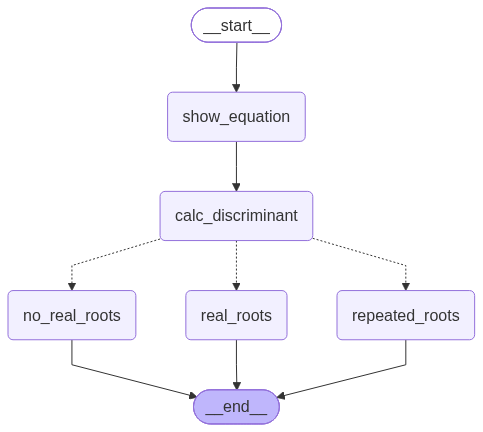

In [45]:
workflow

In [46]:
initial_state = {
    "a" : 4,
    "b" : -5,
    "c" : -4
}
final_state = workflow.invoke(initial_state)
final_state

{'a': 4,
 'b': -5,
 'c': -4,
 'equation': '4x2-5x-4',
 'discriminant': 89,
 'final_result': 'The real roots are 1.8042476415070754 and -0.5542476415070754'}